# Systemy inspekcji wizualnej
## Laboratorium 3
Temat: Histogram, transformacje punktowe i operacje arytmetyczne. Wzorzec statystyczny wyrobu.

Instrukcję opracował: dr inż. Łukasz Jeleń

Wrocław 2026

---

Nazwisko i Imię: Aleksander Łyskawa 

Nr albumu: 275462

Data wykonania ćwiczenia: 27.10.2026

w celu zachowania przeniesienia do kolejnej linii należy się upewnić, że na końcu linii znajdują się 2 spacje

***

# 0. Zasady realizacji ćwiczenia

Notatnik składa się z dwóch części o odmiennym charakterze:

| Część | Charakter | Sposób realizacji | Punkty |
|---|---|---|---|
| **Sekcja 2 — Tutorial** | kod kompletny i uruchamialny, po każdym punkcie krótkie ćwiczenie kontrolne | komórki należy uruchamiać kolejno, zapoznając się z komentarzem, a następnie wykonać ćwiczenie **Do wykonania** | nd. |
| **Sekcja 3 — Zadania** | kod należy napisać samodzielnie | należy rozwiązać zadania i wypełnić komórki *Obserwacje i wnioski* | 30 |

**Zakres pracy.** Należy przesłać notatnik z uzupełnioną **sekcją 2 i sekcją 3**, **wykonanymi komórkami** (widoczne wyniki) oraz wypełnionymi komórkami *Obserwacje i wnioski*. Notatnik bez wypełnionych obserwacji nie będzie oceniony.

**Nazwa pliku:** `Lab3_Nazwisko_NrAlbumu.ipynb`. 

**Uwaga.** W punkcie 1.2 należy wpisać własny numer albumu. Steruje on losowaniem próbki obrazów, na której pracuje się przez całe ćwiczenie — każda osoba otrzymuje inny podzbiór, a zatem inne wyniki liczbowe.

***

# 1. Dane i narzędzia

W laboratorium 2 wada była wykrywana przez porównanie obrazu badanego z **jednym** obrazem wzorcowym. Na obrazach syntetycznych działało to bez zarzutu, ponieważ egzemplarz wzorcowy i badany różniły się wyłącznie wadą.

Na zdjęciach rzeczywistych wyrobów to założenie nie zawsze zadziała, bo każdy egzemplarz jest nieco inny, inaczej ułożony i inaczej oświetlony. Odejmowanie od pojedynczego wzorca daje wtedy fałszywe rezultaty na całej powierzchni. To ćwiczenie buduje **wzorzec statystyczny** — opisujący nie jeden egzemplarz, lecz całą populację dobrych wyrobów.

## 1.1 Zbiór danych

Pracujemy na rzeczywistym zbiorze zdjęć odlewanych wirników pomp, pochodzącym z linii produkcyjnej.

**Zbiór:** *casting product image data for quality inspection*
**Autor:** Ravirajsinh Dabhi
**Adres:** https://www.kaggle.com/datasets/ravirajsinh45/real-life-industrial-dataset-of-casting-product
**Licencja:** CC BY-NC-SA 4.0 wolno używać do celów dydaktycznych.

**Pobranie przez stronę.** Po zalogowaniu na Kaggle należy pobrać zbiór i rozpakować otrzymane archiwum do katalogu z notatnikiem.

**Pobranie z wiersza poleceń** (wymaga pakietu `kaggle` i pliku `kaggle.json` z kluczem API):

```
pip install kaggle
kaggle datasets download -d ravirajsinh45/real-life-industrial-dataset-of-casting-product
unzip real-life-industrial-dataset-of-casting-product.zip -d casting
```

**W Google Colab** archiwum można wgrać ręcznie przez panel po lewej stronie, a następnie rozpakować poleceniem `!unzip`.

**Czego szukamy w archiwum.** Zbiór zawiera dwa warianty rozmiaru obrazów. Pracujemy na wariancie **300×300 px w odcieniach szarości**, w którym zdjęcia są rozdzielone na katalogi:

| Katalog | Zawartość |
|---|---|
| `ok_front` | wyroby **bez wad** (klasa OK) |
| `def_front` | wyroby **z wadami odlewniczymi** (klasa NOK) |

Katalogi te występują osobno dla części uczącej (`train`) i testowej (`test`). Komórka w punkcie 1.3 odnajduje je samodzielnie w rozpakowanym drzewie i wypisuje rzeczywistą liczbę plików — **te liczby należy odczytać i podać w obserwacjach**, a nie przepisywać z instrukcji.

## 1.2 Konfiguracja

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("OpenCV:", cv2.__version__)

# --- katalog, do ktorego rozpakowano archiwum z Kaggle -----------------
DANE = Path("casting")

# --- TUTAJ WPISZ SWOJ NUMER ALBUMU ------------------------------------
NR_ALBUMU = 275462
# ----------------------------------------------------------------------
rng = np.random.default_rng(NR_ALBUMU)
print("ziarno losowania:", NR_ALBUMU)


def pokaz(*obrazy, tytuly=None, cmap="gray", rozmiar=3.6, zakres=(0, 255)):
    """Wyswietla jeden lub wiele obrazow obok siebie."""
    n = len(obrazy)
    fig, osie = plt.subplots(1, n, figsize=(rozmiar * n, rozmiar))
    if n == 1:
        osie = [osie]
    for i, (ax, img) in enumerate(zip(osie, obrazy)):
        if img.ndim == 2:
            ax.imshow(img, cmap=cmap, vmin=zakres[0], vmax=zakres[1])
        else:
            ax.imshow(img)
        ax.set_title(tytuly[i] if tytuly else "")
        ax.axis("off")
    plt.tight_layout()
    plt.show()

OpenCV: 5.0.0
ziarno losowania: 275462


## 1.3 Odnalezienie i wczytanie danych

Poniższa komórka przeszukuje rozpakowane archiwum, odnajduje katalogi klas i wypisuje, co faktycznie zostało pobrane. Jeżeli zgłosi błąd, należy poprawić wartość zmiennej `DANE`.

In [22]:
ROZSZERZENIA = (".jpeg", ".jpg", ".png", ".bmp")


def znajdz_klase(katalog, nazwa):
    """Odnajduje w drzewie wszystkie katalogi o zadanej nazwie i zwraca liste plikow."""
    katalog = Path(katalog)
    if not katalog.exists():
        raise FileNotFoundError(
            f"Katalog {katalog.resolve()} nie istnieje. "
            "Nalezy poprawic zmienna DANE w punkcie 1.2.")
    pliki = []
    for podkatalog in sorted(p for p in katalog.rglob(nazwa) if p.is_dir()):
        pliki += sorted(p for p in podkatalog.iterdir()
                        if p.suffix.lower() in ROZSZERZENIA)
    if not pliki:
        raise FileNotFoundError(
            f"W drzewie {katalog.resolve()} nie znaleziono plikow w katalogu '{nazwa}'.")
    return pliki


PLIKI_OK = znajdz_klase(DANE, "ok_front")
PLIKI_NOK = znajdz_klase(DANE, "def_front")

print(f"klasa OK  (ok_front) : {len(PLIKI_OK):5d} plikow")
print(f"klasa NOK (def_front): {len(PLIKI_NOK):5d} plikow")

probny = cv2.imread(str(PLIKI_OK[0]), cv2.IMREAD_GRAYSCALE)
print("\nprzykladowy plik     :", PLIKI_OK[0].name)
print("ksztalt              :", probny.shape)
print("typ danych           :", probny.dtype)
print("zakres wartosci      :", probny.min(), "-", probny.max())

klasa OK  (ok_front) :  3137 plikow
klasa NOK (def_front):  4211 plikow

przykladowy plik     : cast_ok_0_10.jpeg
ksztalt              : (300, 300)
typ danych           : uint8
zakres wartosci      : 0 - 252


OK : (300, 300, 300) uint8
NOK: (300, 300, 300) uint8


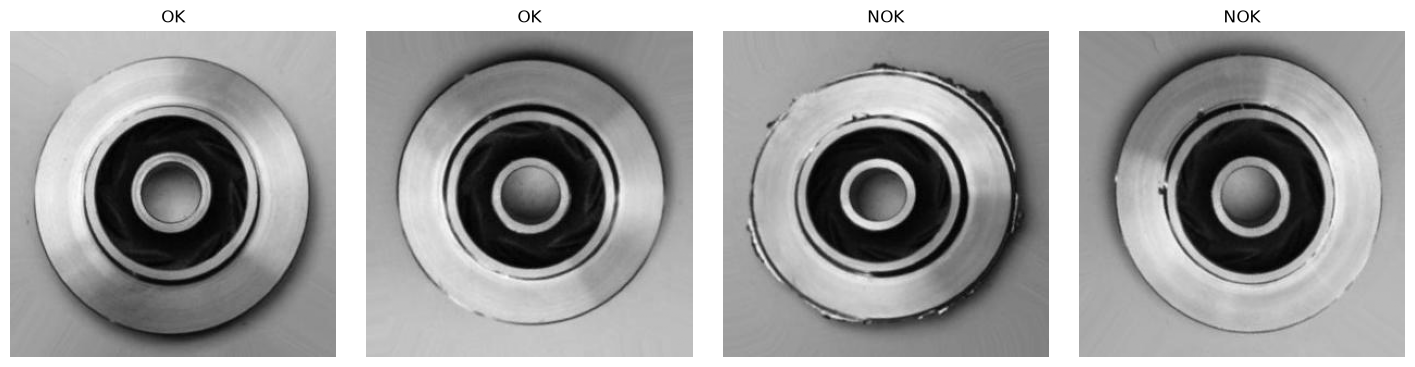

In [23]:
def wczytaj_zbior(pliki, n=None, rozmiar=None):
    """Wczytuje liste plikow jako tablice (n, h, w) w odcieniach szarosci.

    n       - liczba obrazow do wylosowania; None oznacza wszystkie
    rozmiar - (h, w) do ewentualnego przeskalowania; None zostawia oryginalny
    """
    if n is not None and n < len(pliki):
        wybrane = rng.choice(np.array(pliki, dtype=object), size=n, replace=False)
    else:
        wybrane = pliki
    obrazy = []
    for p in wybrane:
        img = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise FileNotFoundError(f"Nie udalo sie wczytac: {p}")
        if rozmiar is not None and img.shape != rozmiar:
            img = cv2.resize(img, (rozmiar[1], rozmiar[0]), interpolation=cv2.INTER_AREA)
        obrazy.append(img)
    return np.stack(obrazy)


OK = wczytaj_zbior(PLIKI_OK, n=300, rozmiar=probny.shape)
NOK = wczytaj_zbior(PLIKI_NOK, n=300, rozmiar=probny.shape)
print("OK :", OK.shape, OK.dtype)
print("NOK:", NOK.shape, NOK.dtype)

pokaz(OK[0], OK[1], NOK[0], NOK[1],
      tytuly=["OK", "OK", "NOK", "NOK"])

# Obserwacje: zbior zawiera 3137 obrazow OK i 4211 obrazow NOK.
# Do tutoriala wczytano po 300 obrazow kazdej klasy, o rozmiarze 300x300 px.
# Typ danych to uint8. Zakres 0-252 dotyczy pierwszego sprawdzanego obrazu.


***

# 2. Ćwiczenia

Komórki należy uruchamiać kolejno, zapoznając się z komentarzem. Z przedstawionych tu rozwiązań należy korzystać przy realizacji zadań z sekcji 3.

Każdy punkt zakończony jest krótkim ćwiczeniem **Do wykonania**, stanowiącym modyfikację kodu przedstawionego wcześniej.

## 2.1 Histogram klasy, a nie pojedynczego obrazu

Histogram jednego zdjęcia mówi o tym jednym egzemplarzu. Do projektowania systemu inspekcji potrzebna jest charakterystyka **całej klasy** wyrobów, czyli histogram uśredniony po wielu obrazach.

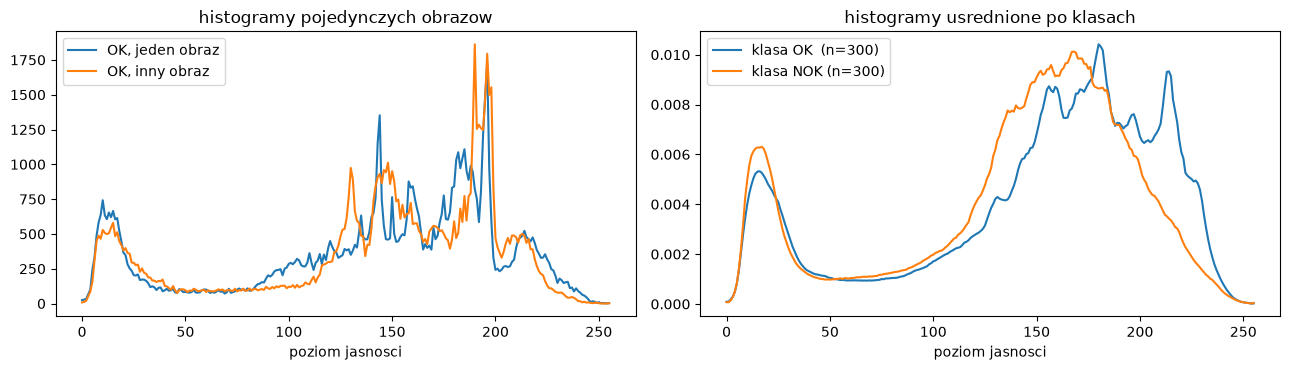

srednia jasnosc klasy OK : 150.43
srednia jasnosc klasy NOK: 139.56


In [24]:
def histogram_klasy(zbior):
    """Usredniony histogram calej klasy obrazow (256 slupkow, znormalizowany)."""
    h = np.zeros(256, np.float64)
    for img in zbior:
        h += cv2.calcHist([img], [0], None, [256], [0, 256]).ravel()
    return h / h.sum()


h_ok = histogram_klasy(OK)
h_nok = histogram_klasy(NOK)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].plot(cv2.calcHist([OK[0]], [0], None, [256], [0, 256]).ravel(), label="OK, jeden obraz")
ax[0].plot(cv2.calcHist([OK[1]], [0], None, [256], [0, 256]).ravel(), label="OK, inny obraz")
ax[0].set_title("histogramy pojedynczych obrazow"); ax[0].legend(); ax[0].set_xlabel("poziom jasnosci")

ax[1].plot(h_ok, label=f"klasa OK  (n={len(OK)})")
ax[1].plot(h_nok, label=f"klasa NOK (n={len(NOK)})")
ax[1].set_title("histogramy usrednione po klasach"); ax[1].legend(); ax[1].set_xlabel("poziom jasnosci")
plt.tight_layout(); plt.show()

print(f"srednia jasnosc klasy OK : {OK.mean():6.2f}")
print(f"srednia jasnosc klasy NOK: {NOK.mean():6.2f}")

Histogramy obu klas w znacznym stopniu się pokrywają. Wniosek jest praktyczny i ważny: **sama jasność globalna nie wystarcza do odróżnienia wyrobu dobrego od wadliwego**. Wada zajmuje ułamek powierzchni, więc jej wkład do histogramu całego obrazu jest znikomy. Potrzebna jest informacja o tym, *gdzie* na wyrobie wartość odbiega od normy. O tym będzie punkt 2.4.

### Do wykonania 2.1

Należy policzyć uśredniony histogram klasy OK dla 20 oraz dla 300 obrazów i wykreślić oba na jednym rysunku.

Należy podać maksymalną różnicę między tymi histogramami i na tej podstawie ocenić, czy 20 obrazów wystarcza do opisania klasy.

Maksymalna roznica: 0.003097
Roznica w punktach procentowych: 0.310


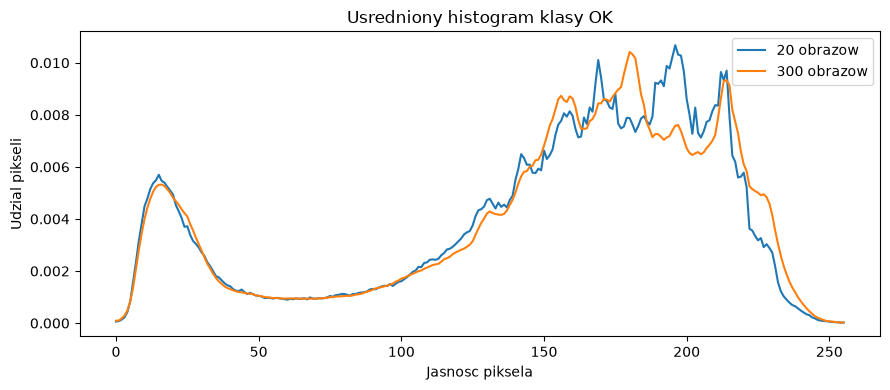

In [25]:
h20 = histogram_klasy(OK[:20])
h300 = histogram_klasy(OK[:300])

diff = np.abs(h20 - h300)

print(f"Maksymalna roznica: {diff.max():.6f}")
print(f"Roznica w punktach procentowych: {100 * diff.max():.3f}")

plt.figure(figsize=(9, 4))
plt.plot(h20, label="20 obrazow")
plt.plot(h300, label="300 obrazow")
plt.xlabel("Jasnosc piksela")
plt.ylabel("Udzial pikseli")
plt.title("Usredniony histogram klasy OK")
plt.legend()
plt.tight_layout()
plt.show()

# Maksymalna roznica wynosi 0.003097
# 20 obrazow oddaje ogolny ksztalt histogramu, ale widoczne sa lokalne roznice.
# W tej probce 20 obrazow wystarcza do przyblizonego opisu klasy.
# Do dokladniejszego opisu wybieram 300 obrazow.

## 2.2 Transformacje punktowe

Transformacja punktowa zmienia wartość piksela wyłącznie na podstawie jego własnej wartości, niezależnie od otoczenia. Realizuje się ją tablicą **LUT** (*look-up table*) o 256 pozycjach. Jest to jednocześnie najszybszy sposób, ponieważ wartość każdego piksela jest po prostu odczytywana z tablicy.

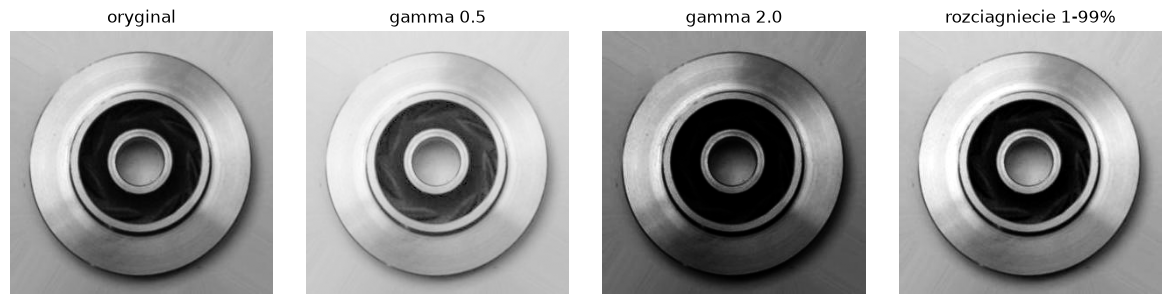

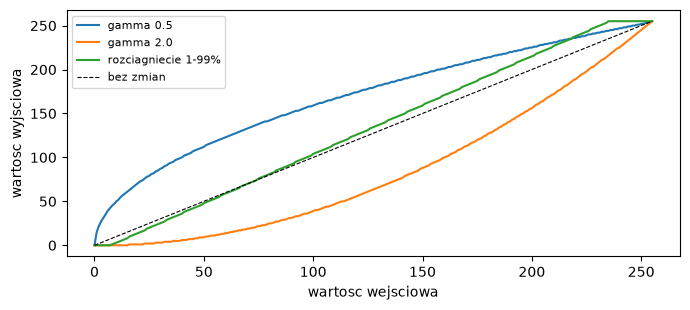

In [26]:
def lut_gamma(g):
    """Tablica przekodowania dla korekcji gamma."""
    x = np.arange(256, dtype=np.float64) / 255.0
    return np.clip((x ** g) * 255.0, 0, 255).astype(np.uint8)


def lut_rozciagniecie(lo, hi):
    """Liniowe rozciagniecie zakresu [lo, hi] na pelny zakres 0-255."""
    x = np.arange(256, dtype=np.float64)
    y = (x - lo) * 255.0 / max(hi - lo, 1)
    return np.clip(y, 0, 255).astype(np.uint8)


obraz = OK[0]
lo, hi = np.percentile(obraz, [1, 99])

warianty = {
    "oryginal":            obraz,
    "gamma 0.5":           cv2.LUT(obraz, lut_gamma(0.5)),
    "gamma 2.0":           cv2.LUT(obraz, lut_gamma(2.0)),
    "rozciagniecie 1-99%": cv2.LUT(obraz, lut_rozciagniecie(lo, hi)),
}
pokaz(*warianty.values(), tytuly=list(warianty.keys()), rozmiar=3.0)

plt.figure(figsize=(7, 3.2))
for nazwa in ("gamma 0.5", "gamma 2.0", "rozciagniecie 1-99%"):
    tab = {"gamma 0.5": lut_gamma(0.5), "gamma 2.0": lut_gamma(2.0),
           "rozciagniecie 1-99%": lut_rozciagniecie(lo, hi)}[nazwa]
    plt.plot(tab, label=nazwa)
plt.plot(np.arange(256), "k--", lw=0.8, label="bez zmian")
plt.xlabel("wartosc wejsciowa"); plt.ylabel("wartosc wyjsciowa")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

Dwie transformacje adaptacyjne, dostępne w OpenCV:

- `cv2.equalizeHist` - wyrównanie histogramu dla całego obrazu; rozciąga kontrast, ale wzmacnia szum w obszarach jednorodnych;
- `cv2.createCLAHE` - wyrównanie z ograniczeniem wzmocnienia, liczone w kafelkach; parametr `clipLimit` decyduje o tym, jak mocno wolno wzmocnić kontrast lokalny.

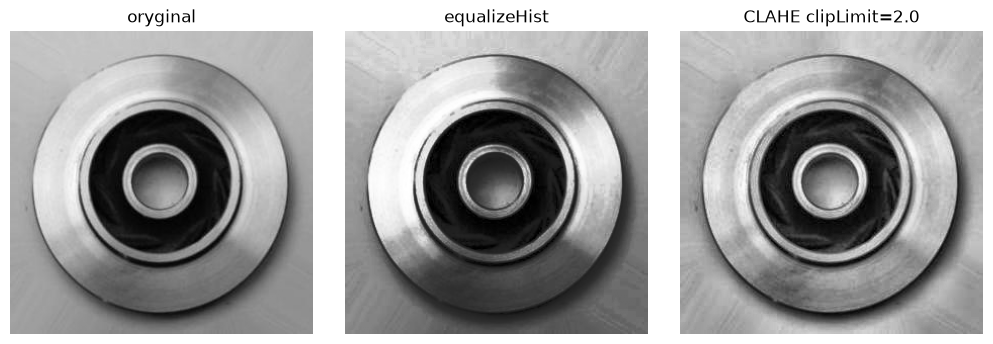

oryginal       srednia=141.14  odch.std= 63.43
equalizeHist   srednia=128.29  odch.std= 73.81
CLAHE          srednia=146.38  odch.std= 59.65


In [27]:
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
pokaz(obraz, cv2.equalizeHist(obraz), clahe.apply(obraz),
      tytuly=["oryginal", "equalizeHist", "CLAHE clipLimit=2.0"], rozmiar=3.4)

for nazwa, img in [("oryginal", obraz),
                   ("equalizeHist", cv2.equalizeHist(obraz)),
                   ("CLAHE", clahe.apply(obraz))]:
    print(f"{nazwa:14s} srednia={img.mean():6.2f}  odch.std={img.std():6.2f}")

### Do wykonania 2.2

Należy zastosować CLAHE do obrazu `OK[0]` dla trzech wartości `clipLimit`: 1.0, 4.0 oraz 20.0, przy niezmienionym `tileGridSize`.

Dla każdego wyniku należy podać odchylenie standardowe obrazu i wskazać, przy której wartości `clipLimit` wzmocnienie kontrastu zaczyna uwypuklać szum zamiast struktury wyrobu.

clipLimit | Odchylenie standardowe
      1.0 | 61.47
      4.0 | 57.61
     20.0 | 58.34


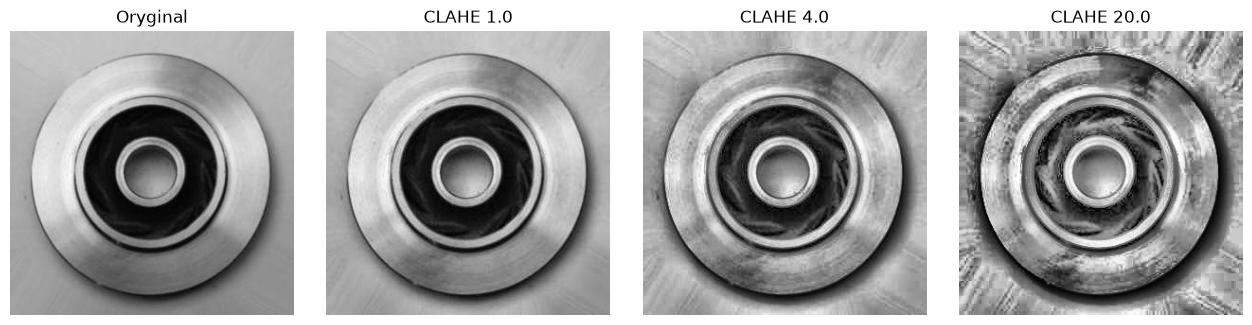

In [28]:
img = OK[0]
imgs = [img]
tags = ["Oryginal"]

print("clipLimit | Odchylenie standardowe")

for clip in (1.0, 4.0, 20.0):
    clahe = cv2.createCLAHE(
        clipLimit=clip,
        tileGridSize=(8, 8)
    )

    out = clahe.apply(img)

    print(f"{clip:9.1f} | {out.std():.2f}")

    imgs.append(out)
    tags.append(f"CLAHE {clip}")

pokaz(*imgs, tytuly=tags, rozmiar=3.2)

# Odchylenia standardowe:
# clipLimit=1.0: 61.47; clipLimit=4.0: 57.61; clipLimit=20.0: 58.34.
# Przy 4.0 zaczyna byc wyrazniej widoczna drobna ziarnistosc tla.
# Przy 20.0 szum i artefakty sa silnie uwypuklone.
# Odchylenie calego obrazu nie rosnie tutaj monotonicznie z clipLimit,
# dlatego ocene wzmacniania szumu opieram rowniez na wygladzie obrazu.

## 2.3 Operacje arytmetyczne na zbiorze obrazów

Obraz średni klasy OK jest wzorcem uśrednionym po całej populacji wyrobów prawidłowych. Obraz odchylenia standardowego mówi natomiast, **jak bardzo wyrób ma prawo różnić się od tego wzorca w danym miejscu** i to jest informacja, której pojedynczy wzorzec z laboratorium 2 nie zawierał.

Obliczenia wykonuje się na typie zmiennoprzecinkowym, `uint8` nie nadaje się do uśredniania, ponieważ zaokrągla wartości przy przepełnieniu.

obraz sredni     : zakres 21.2 - 184.2
obraz odchylenia : zakres 10.4 - 79.7, mediana 40.92


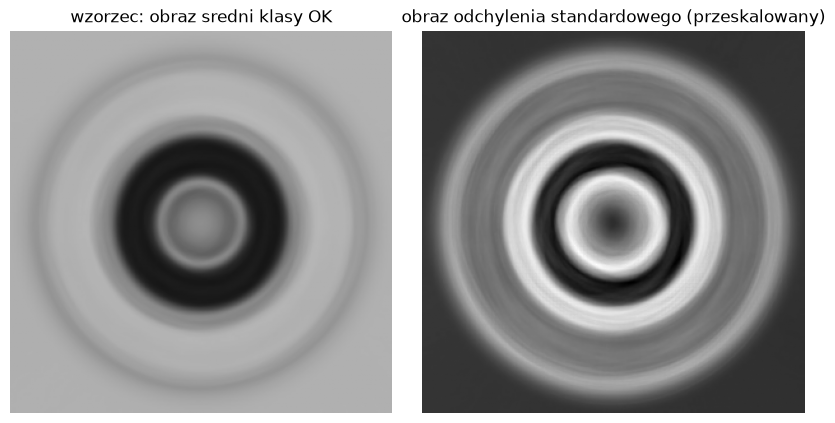

In [29]:
ok_f = OK.astype(np.float32)

srednia = ok_f.mean(axis=0)
odchylenie = ok_f.std(axis=0)

print(f"obraz sredni     : zakres {srednia.min():.1f} - {srednia.max():.1f}")
print(f"obraz odchylenia : zakres {odchylenie.min():.1f} - {odchylenie.max():.1f}, "
      f"mediana {np.median(odchylenie):.2f}")

pokaz(srednia.astype(np.uint8),
      cv2.normalize(odchylenie, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8),
      tytuly=["wzorzec: obraz sredni klasy OK",
              "obraz odchylenia standardowego (przeskalowany)"], rozmiar=4.2)

Jasne obszary na mapie odchylenia to miejsca, w których wyroby dobre naturalnie się od siebie różnią: krawędzie, elementy ustawiane z luzem, obszary o zmiennym oświetleniu. **Szukanie wad w tych miejscach z użyciem stałego progu zawsze będzie generowało fałszywe alarmy.**

### Do wykonania 2.3

Należy policzyć wzorzec statystyczny (obraz średni i obraz odchylenia) dwukrotnie: z 30 obrazów klasy OK oraz z 300 obrazów klasy OK.

Należy wyświetlić obie mapy odchylenia obok siebie i podać ich medianę. Na tej podstawie trzeba ocenić, czy 30 obrazów wystarcza do zbudowania wzorca.

Mediana dla 30 obrazow:  36.96
Mediana dla 300 obrazow: 40.92
Srednia bezwzgledna roznica map: 4.01


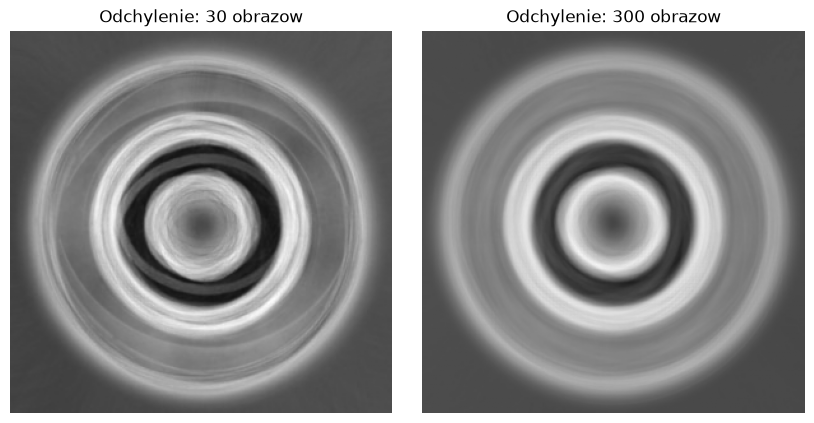

In [30]:
a = OK[:30].astype(np.float32)
b = OK[:300].astype(np.float32)

mean30 = a.mean(axis=0)
sd30 = a.std(axis=0)

mean300 = b.mean(axis=0)
sd300 = b.std(axis=0)

print(f"Mediana dla 30 obrazow:  {np.median(sd30):.2f}")
print(f"Mediana dla 300 obrazow: {np.median(sd300):.2f}")
print(
    f"Srednia bezwzgledna roznica map: "
    f"{np.abs(sd30 - sd300).mean():.2f}"
)

hi = max(sd30.max(), sd300.max())

pokaz(
    sd30, sd300,
    tytuly=["Odchylenie: 30 obrazow", "Odchylenie: 300 obrazow"],
    zakres=(0, hi),
    rozmiar=4.2
)

# Mediana odchylenia: 36.96 dla 30 obrazow i 40.92 dla 300 obrazow.
# Srednia bezwzgledna roznica map wynosi 4.01 poziomu jasnosci.
# 30 obrazow pokazuje glowne obszary zmiennosci,
# ale mediana jest o ok. 9.7% nizsza i widoczne sa lokalne roznice map.
# Do dokladnego wzorca inspekcyjnego wybieram 300 obrazow.
# Obie mapy wyswietlono w tej samej skali jasnosci.

## 2.4 Odległość obrazu od wzorca

Mając wzorzec i mapę dopuszczalnej zmienności, odchylenie badanego obrazu wyraża się w **jednostkach odchylenia standardowego** w każdym punkcie:

$$ z(x,y) = \frac{|\,b(x,y) - m(x,y)\,|}{\sigma(x,y) + \varepsilon} $$

gdzie $b$ to obraz badany, $m$ — obraz średni, $\sigma$ — obraz odchylenia, a $\varepsilon$ zabezpiecza przed dzieleniem przez zero. Wartość $z = 3$ oznacza odchylenie trzykrotnie większe niż typowa zmienność wyrobów dobrych w tym właśnie punkcie.

Zaletą takiego ujęcia jest to, że **próg przestaje zależeć od miejsca na wyrobie**: jedna wartość obowiązuje zarówno w obszarze stabilnym, jak i przy krawędzi.

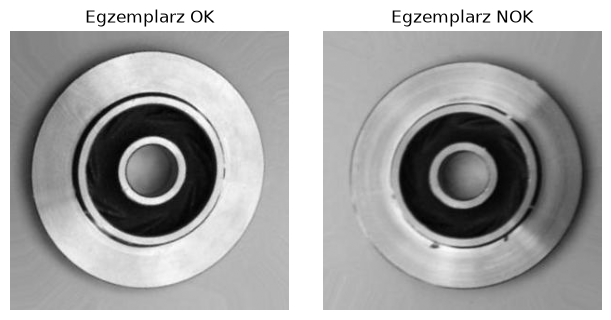

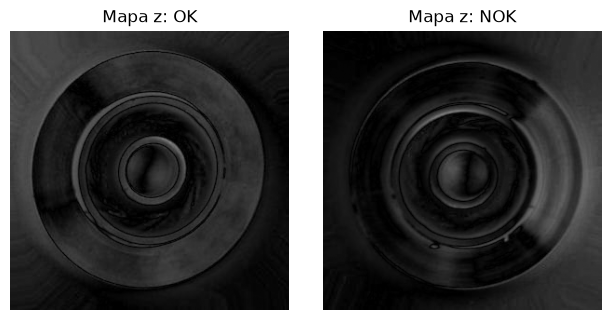

99. percentyl mapy z, po 10 egzemplarzy z kazdej klasy:
  OK : srednia  2.78   zakres  1.88 -  4.89
  NOK: srednia  2.99   zakres  1.82 -  4.97


In [31]:
EPS = 2.0      # zabezpieczenie przed dzieleniem przez zero i wzmacnianiem szumu


def mapa_z(obraz, srednia, odchylenie, eps=EPS):
    """Mapa odchylenia od wzorca, wyrazona w jednostkach odchylenia standardowego."""
    return np.abs(obraz.astype(np.float32) - srednia) / (odchylenie + eps)


badany_ok = wczytaj_zbior(PLIKI_OK, n=1, rozmiar=probny.shape)[0]
badany_nok = wczytaj_zbior(PLIKI_NOK, n=1, rozmiar=probny.shape)[0]

z_ok = mapa_z(badany_ok, srednia, odchylenie)
z_nok = mapa_z(badany_nok, srednia, odchylenie)

pokaz(badany_ok, badany_nok,
      tytuly=["Egzemplarz OK", "Egzemplarz NOK"], rozmiar=3.2)

pokaz(z_ok, z_nok,
      tytuly=["Mapa z: OK", "Mapa z: NOK"],
      rozmiar=3.2, zakres=(0, 6))

# pojedynczy obraz to zbyt malo, zeby cokolwiek stwierdzic - liczymy dla 10 sztuk
def percentyl99(zbior):
    return np.array([np.percentile(mapa_z(img, srednia, odchylenie), 99) for img in zbior])

p_ok = percentyl99(wczytaj_zbior(PLIKI_OK, n=10, rozmiar=probny.shape))
p_nok = percentyl99(wczytaj_zbior(PLIKI_NOK, n=10, rozmiar=probny.shape))

print("99. percentyl mapy z, po 10 egzemplarzy z kazdej klasy:")
print(f"  OK : srednia {p_ok.mean():5.2f}   zakres {p_ok.min():5.2f} - {p_ok.max():5.2f}")
print(f"  NOK: srednia {p_nok.mean():5.2f}   zakres {p_nok.min():5.2f} - {p_nok.max():5.2f}")

Aby podjąć decyzję dla całego obrazu, mapę trzeba sprowadzić do **jednej liczby**. Maksimum jest wrażliwe na pojedynczy zaszumiony piksel, dlatego praktyczniej jest użyć wysoki percentyl albo liczbę pikseli przekraczających ustalony poziom.

Należy zwrócić uwagę na zakresy wypisane powyżej: **klasy zachodzą na siebie**. Pojedynczy egzemplarz NOK potrafi wypaść „spokojniej" niż egzemplarz OK, dlatego o skuteczności detektora nie wolno wnioskować z jednego czy dwóch obrazów, ale potrzebny jest rozkład policzony na dziesiątkach sztuk. Tym właśnie zajmuje się zadanie 3.

### Do wykonania 2.4

Dla 30 obrazów klasy OK i 30 obrazów klasy NOK należy policzyć dwie wielkości opisujące mapę z: jej **maksimum** oraz jej **99. percentyl**.

Dla obu wielkości należy podać wartość średnią w każdej klasie i wskazać, która z nich lepiej rozdziela klasy. Odpowiedź należy uzasadnić liczbami.

In [32]:
max_ok = []
max_nok = []
p99_ok = []
p99_nok = []

for img in OK[:30]:
    z = mapa_z(img, srednia, odchylenie)
    max_ok.append(z.max())
    p99_ok.append(np.percentile(z, 99))

for img in NOK[:30]:
    z = mapa_z(img, srednia, odchylenie)
    max_nok.append(z.max())
    p99_nok.append(np.percentile(z, 99))

print("Miara       | Srednia OK | Srednia NOK | Rozdzielnosc")

for tag, a, b in [
    ("Maksimum", max_ok, max_nok),
    ("Percentyl99", p99_ok, p99_nok)
]:
    a = np.array(a)
    b = np.array(b)
    sd = np.sqrt((a.var() + b.var()) / 2)
    d = abs(a.mean() - b.mean()) / sd

    print(
        f"{tag:11s} | {a.mean():10.3f} | "
        f"{b.mean():11.3f} | {d:.3f}"
    )

# Maksimum: srednia OK=3.800, srednia NOK=5.506, rozdzielnosc=0.865.
# Percentyl99: srednia OK=2.322, srednia NOK=2.606, rozdzielnosc=0.581.
# W tej probce lepiej rozdziela klasy maksimum mapy z.
# Zakresy obu klas nadal sie pokrywaja.
# Obrazy OK uczestniczyly w budowie wzorca, wiec jest to porownanie
# tutorialowe. Osobna ocena na nowych obrazach znajduje sie w zadaniu 3.


Miara       | Srednia OK | Srednia NOK | Rozdzielnosc
Maksimum    |      3.800 |       5.506 | 0.865
Percentyl99 |      2.322 |       2.606 | 0.581


***

# 3. Zadania na ocenę

Zadania 1–3 są obowiązkowe, zadanie 4 dodatkowe. Przy każdym zadaniu należy wypełnić komórkę *Obserwacje i wnioski*; sam kod bez wniosków nie wystarcza do zaliczenia.

| Zadanie | Temat | Punkty |
|---|---|---|
| 1 | Wzorzec statystyczny wyrobu | 8 |
| 2 | Dobór transformacji punktowej | 10 |
| 3 | Detektor progowy i jego ocena | 12 |
| 4 | (dodatkowe) Diagnoza błędów detektora | 6 |

Funkcje należy implementować **zgodnie z podanymi sygnaturami**, co usprawnia sprawdzanie prac.

**Wyniki liczbowe będą się różnić między osobami**, ponieważ próbka obrazów zależy od numeru albumu wpisanego w punkcie 1.2. Wyniki identyczne z cudzymi oznaczają, że numer nie został zmieniony. :)

## Zadanie 1 (8 pkt)

Należy napisać funkcję `wzorzec_statystyczny(zbior)` zwracającą krotkę `(srednia, odchylenie)` zawierającą dwie tablice `float32` o rozmiarze pojedynczego obrazu.

Następnie, korzystając z tej funkcji:

1. zbudować wzorzec z **200 obrazów klasy OK**,
2. wyświetlić obraz średni oraz mapę odchylenia,
3. wskazać na mapie odchylenia **trzy obszary o największej zmienności** i nanieść na nią prostokąty okalające te obszary,
4. podać reguły, według których odrzucono by te obszary z inspekcji (np. udział powierzchni, wartość progowa odchylenia).

Liczba obrazow: 200
Srednia: (300, 300) float32
Odchylenie: (300, 300) float32

Obszar | x   | y   | Srednie odchylenie
     1 |  60 | 120 | 61.70
     2 | 210 | 150 | 61.29
     3 | 120 |  60 | 59.39

Wykluczone piksele: 2700
Przyblizona powierzchnia wyrobu: 53077 pikseli
Wykluczony udzial powierzchni wyrobu: 5.09%
Wykluczony udzial calego obrazu: 3.00%


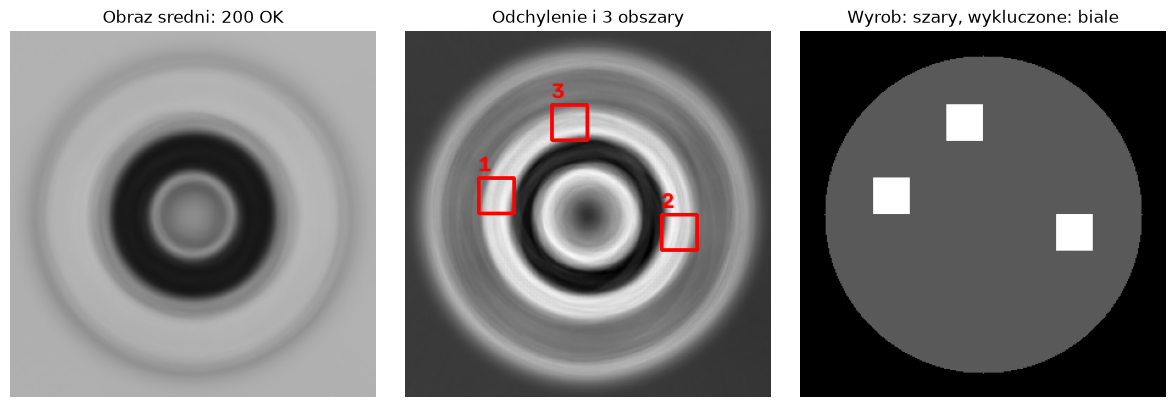

In [33]:
def wzorzec_statystyczny(zbior):
    arr = zbior.astype(np.float32)
    mean = arr.mean(axis=0)
    std = arr.std(axis=0)
    return mean, std


mean, std = wzorzec_statystyczny(OK[:200])
h, w = mean.shape

print("Liczba obrazow:", len(OK[:200]))
print("Srednia:", mean.shape, mean.dtype)
print("Odchylenie:", std.shape, std.dtype)

# Ranking kwadratow wedlug sredniego odchylenia
size = 30
cells = []

for y in range(0, h - size + 1, size):
    for x in range(0, w - size + 1, size):
        score = std[y:y + size, x:x + size].mean()
        cells.append((float(score), x, y))

cells.sort(reverse=True)
boxes = []

for score, x, y in cells:
    near = any(
        abs(x - bx) <= size and abs(y - by) <= size
        for _, bx, by in boxes
    )

    if near:
        continue

    boxes.append((score, x, y))

    if len(boxes) == 3:
        break

view = cv2.normalize(std, None, 0, 255, cv2.NORM_MINMAX)
view = cv2.cvtColor(view.astype(np.uint8), cv2.COLOR_GRAY2RGB)

skip = np.zeros((h, w), dtype=np.uint8)

print("\nObszar | x   | y   | Srednie odchylenie")

for i, (score, x, y) in enumerate(boxes, start=1):
    skip[y:y + size, x:x + size] = 255

    cv2.rectangle(
        view,
        (x, y),
        (x + size - 1, y + size - 1),
        (255, 0, 0),
        2
    )

    cv2.putText(
        view, str(i), (x, y - 5),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6, (255, 0, 0), 2
    )

    print(f"{i:6d} | {x:3d} | {y:3d} | {score:.2f}")

part = np.zeros((h, w), dtype=np.uint8)
cv2.circle(part, (w // 2, h // 2), 130, 255, -1)

cut = (skip > 0) & (part > 0)

share = 100 * np.count_nonzero(cut) / np.count_nonzero(part)
frame_share = 100 * np.count_nonzero(skip) / skip.size

print(f"\nWykluczone piksele: {np.count_nonzero(cut)}")
print(
    f"Przyblizona powierzchnia wyrobu: "
    f"{np.count_nonzero(part)} pikseli"
)
print(f"Wykluczony udzial powierzchni wyrobu: {share:.2f}%")
print(f"Wykluczony udzial calego obrazu: {frame_share:.2f}%")

mask_view = np.zeros((h, w), dtype=np.uint8)
mask_view[part > 0] = 90
mask_view[cut] = 255

pokaz(
    mean, view, mask_view,
    tytuly=[
        "Obraz sredni: 200 OK",
        "Odchylenie i 3 obszary",
        "Wyrob: szary, wykluczone: biale"
    ],
    rozmiar=4.0
)

**Obserwacje i wnioski**

*Co fizycznie znajduje się w obszarach o największej zmienności? czy wynika to z wyrobu, z jego ułożenia, czy z oświetlenia? Dlaczego stały próg zastosowany w tych obszarach musiałby prowadzić do fałszywych alarmów? Jaki udział powierzchni wyrobu trzeba było wyłączyć z inspekcji?*

> 

WNIOSKI:

Wybrane obszary lezą przy granicy ciemnej części środkowej i jaśniejszego pierścienia. Ich zmienność prawdopodobnie wynika z róznic ułozenia, geometrii i oświetlenia. Niski, stały próg róznicy jasności moze tam powodować fałszywe alarmy.

Zaproponowano pomijanie trzech rozdzielonych kwadratów 30×30 px o najwyzszym średnim odchyleniu. Łącznie zajmują 2700 pikseli: około 5,09% obszaru wyrobu przyblizonego kołem o promieniu 130 px oraz 3% kadru. Pomijanie tych miejsc oznacza równiez ryzyko przeoczenia znajdujących się tam wad.

## Zadanie 2 (10 pkt)

Należy napisać funkcję `rozdzielnosc(a, b)` obliczającą miarę rozdzielności dwóch zbiorów liczb:

$$ d = \frac{|\,\overline{a} - \overline{b}\,|}{\sqrt{\tfrac{1}{2}\left(s_a^2 + s_b^2\right)}} $$

gdzie $\overline{a}$, $\overline{b}$ to wartości średnie, a $s_a$, $s_b$ to odchylenia standardowe. Im większa wartość $d$, tym lepiej będą rozdzielone klasy.

Następnie należy sprawdzić, czy transformacja punktowa zastosowana **przed** zbudowaniem wzorca poprawia rozdzielność klas:

1. wybrać trzy transformacje punktowe spośród omówionych w punkcie 2.2 (gamma, rozciągnięcie, `equalizeHist`, CLAHE) i dobrać ich parametry,
2. dla każdego wariantu, w tym dla obrazów bez transformacji, zbudować wzorzec ze 150 obrazów OK, a następnie policzyć 99. percentyl mapy z dla 100 innych obrazów OK i 100 obrazów NOK,
3. dla każdego wariantu podać wartość `rozdzielnosc(...)` między tymi dwoma zbiorami liczb,
4. zestawić wyniki w tabeli i wybrać wariant najlepszy.

**Transformację należy stosować konsekwentnie**  do obrazów budujących wzorzec oraz do obrazów badanych.

In [34]:
from time import perf_counter


def rozdzielnosc(a, b):
    a = np.asarray(a, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)

    gap = abs(a.mean() - b.mean())
    sd = np.sqrt((a.var() + b.var()) / 2)

    if sd == 0:
        return 0.0 if gap == 0 else float("inf")

    return float(gap / sd)


paths_ok = [p for p in PLIKI_OK if "train" in p.parts]
paths_nok = [p for p in PLIKI_NOK if "train" in p.parts]

rng2 = np.random.default_rng(NR_ALBUMU)

sel_ok = rng2.choice(
    np.array(paths_ok, dtype=object), 250, replace=False
)
sel_nok = rng2.choice(
    np.array(paths_nok, dtype=object), 100, replace=False
)

ref = wczytaj_zbior(sel_ok[:150], rozmiar=probny.shape)
val_ok = wczytaj_zbior(sel_ok[150:], rozmiar=probny.shape)
val_nok = wczytaj_zbior(sel_nok, rozmiar=probny.shape)

print("Wzorzec:", len(ref), "OK")
print("Ocena:", len(val_ok), "OK i", len(val_nok), "NOK")


lut = lut_gamma(0.5)
clahe = cv2.createCLAHE(
    clipLimit=2.0, tileGridSize=(8, 8)
)

variants = {
    "Bez zmian": lambda img: img,
    "Gamma 0.5": lambda img: cv2.LUT(img, lut),
    "equalizeHist": cv2.equalizeHist,
    "CLAHE 2.0": clahe.apply
}

rows = []

print(
    "\nWariant      | Srednia OK | Srednia NOK |"
    "       d | Transf. ms/obraz"
)

for name, fn in variants.items():
    ref_t = np.stack([fn(img) for img in ref])
    mean, std = wzorzec_statystyczny(ref_t)

    start = perf_counter()
    ok_t = [fn(img) for img in val_ok]
    nok_t = [fn(img) for img in val_nok]

    ms = (
        1000 * (perf_counter() - start)
        / (len(val_ok) + len(val_nok))
    )

    a = np.array([
        np.percentile(mapa_z(img, mean, std), 99)
        for img in ok_t
    ])

    b = np.array([
        np.percentile(mapa_z(img, mean, std), 99)
        for img in nok_t
    ])

    d = rozdzielnosc(a, b)
    rows.append((name, d, ms))

    print(
        f"{name:12s} | {a.mean():10.3f} | "
        f"{b.mean():11.3f} | {d:7.3f} | {ms:.4f}"
    )

best_name, best_d, best_ms = max(
    rows, key=lambda row: row[1]
)
best_fn = variants[best_name]
base_d = rows[0][1]

print(f"\nNajlepszy wariant: {best_name}")
print(
    f"Zmiana d wzgledem oryginalu: "
    f"{best_d - base_d:+.3f}"
)
print(
    f"Zmiana wzgledna: "
    f"{100 * (best_d / base_d - 1):+.1f}%"
)

Wzorzec: 150 OK
Ocena: 100 OK i 100 NOK

Wariant      | Srednia OK | Srednia NOK |       d | Transf. ms/obraz
Bez zmian    |      2.426 |       2.682 |   0.355 | 0.0043
Gamma 0.5    |      2.607 |       2.926 |   0.456 | 0.0444
equalizeHist |      2.002 |       2.699 |   0.789 | 0.0935
CLAHE 2.0    |      2.506 |       2.665 |   0.247 | 0.1716

Najlepszy wariant: equalizeHist
Zmiana d wzgledem oryginalu: +0.435
Zmiana wzgledna: +122.4%


**Obserwacje i wnioski**

*Który wariant wypadł najlepiej i o ile poprawił rozdzielność względem obrazów bez transformacji? Czy poprawa jest na tyle duża, aby uzasadniała dodatkowy koszt obliczeniowy w systemie pracującym w czasie rzeczywistym? Czy któraś z transformacji pogorszyła wynik i co było tego przyczyną?*

> 

WNIOSKI:

Najlepiej wypadło equalizeHist: rozdzielność wzrosła z około 0,355 do 0,789, czyli o 122,4%. Zmierzony koszt transformacji wyniósł około 0,09 ms na obraz, co przemawia za wykorzystaniem tego wariantu w detektorze. Pełny czas działania wymaga osobnej oceny.

Gamma 0,5 poprawiła wynik do 0,456, natomiast CLAHE 2,0 pogorszyło go do 0,247. Prawdopodobnie lokalne wyrównanie osłabiło róznice jasności istotne dla tej metody. Lepsza widoczność szczegółów nie gwarantuje lepszego rozdzielenia klas.

## Zadanie 3 (12 pkt)

Należy napisać funkcję `ocen_obraz(obraz, srednia, odchylenie, percentyl=99)` zwracającą **jedną liczbę** opisującą odchylenie obrazu od wzorca.

Następnie zbudować i ocenić detektor:

1. wzorzec zbudować ze 150 obrazów klasy OK (wariant transformacji wybrany w zadaniu 2),
2. policzyć wartość `ocen_obraz` dla **200 obrazów OK i 200 obrazów NOK**, **nieużytych** do budowy wzorca,
3. wykreślić rozkłady obu zbiorów wartości na wspólnym wykresie (dwa histogramy),
4. dobrać próg decyzyjny i uzasadnić wybór,
5. podać macierz pomyłek oraz czułość i swoistość,
6. sprawdzić, jak zmieniają się czułość i swoistość dla trzech różnych progów, a wyniki zestawić w tabeli.

**Obrazy użyte do budowy wzorca nie mogą pojawić się w zbiorze testowym.** Naruszenie tej zasady zawyża wynik i jest traktowane jako błąd metodyczny.

Wariant: equalizeHist
Liczba obrazow wzorca: 150
Wybrany prog: 1.7172; wynik >= prog oznacza NOK
Czulosc na walidacji: 90.0%
Swoistosc na walidacji: 22.0%

Zakres wynikow OK:  1.507 - 3.579
Zakres wynikow NOK: 1.521 - 7.890


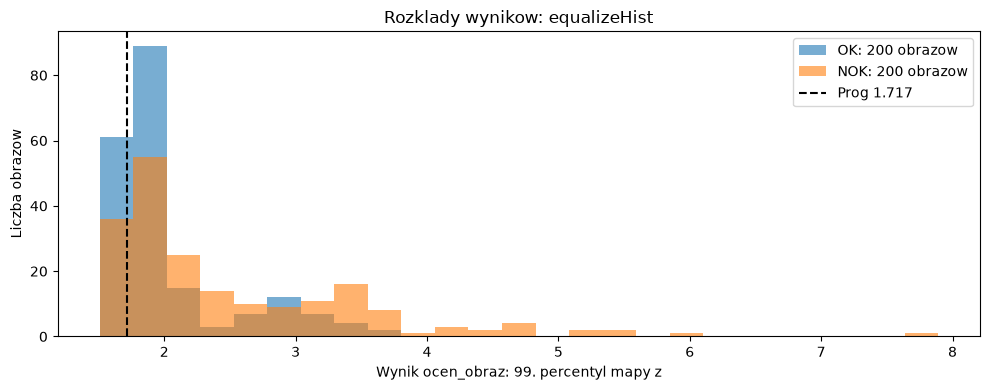


Prog   | Czulosc | Swoistosc | Falszywe alarmy | Przeoczenia
 1.671 |   90.5% |     14.5% |             171 |          19
 1.717 |   87.5% |     19.0% |             162 |          25
 1.801 |   80.0% |     41.5% |             117 |          40

Macierz pomylek dla progu 1.7172:
                Decyzja OK  Decyzja NOK
Prawdziwe OK           38          162
Prawdziwe NOK          25          175
Czulosc: 87.5%
Swoistosc: 19.0%


In [35]:
def ocen_obraz(obraz, srednia, odchylenie, percentyl=99):
    z = mapa_z(obraz, srednia, odchylenie)
    return float(np.percentile(z, percentyl))


ref_t = np.stack([best_fn(img) for img in ref])
mean, std = wzorzec_statystyczny(ref_t)


v_ok = np.array([
    ocen_obraz(best_fn(img), mean, std)
    for img in val_ok
])

v_nok = np.array([
    ocen_obraz(best_fn(img), mean, std)
    for img in val_nok
])


thresholds = np.percentile(v_nok, [5, 10, 20])
t = float(thresholds[1])

print("Wariant:", best_name)
print("Liczba obrazow wzorca:", len(ref))
print(f"Wybrany prog: {t:.4f}; wynik >= prog oznacza NOK")
print(
    f"Czulosc na walidacji: "
    f"{100 * np.mean(v_nok >= t):.1f}%"
)
print(
    f"Swoistosc na walidacji: "
    f"{100 * np.mean(v_ok < t):.1f}%"
)

paths_ok = [p for p in PLIKI_OK if "test" in p.parts]
paths_nok = [p for p in PLIKI_NOK if "test" in p.parts]

rng3 = np.random.default_rng(NR_ALBUMU)

test_paths_ok = rng3.choice(
    np.array(paths_ok, dtype=object), 200, replace=False
)
test_paths_nok = rng3.choice(
    np.array(paths_nok, dtype=object), 200, replace=False
)

assert set(sel_ok).isdisjoint(test_paths_ok)
assert set(sel_nok).isdisjoint(test_paths_nok)

test_ok = wczytaj_zbior(
    test_paths_ok, rozmiar=probny.shape
)
test_nok = wczytaj_zbior(
    test_paths_nok, rozmiar=probny.shape
)

s_ok = np.array([
    ocen_obraz(best_fn(img), mean, std)
    for img in test_ok
])

s_nok = np.array([
    ocen_obraz(best_fn(img), mean, std)
    for img in test_nok
])

print(
    f"\nZakres wynikow OK:  "
    f"{s_ok.min():.3f} - {s_ok.max():.3f}"
)
print(
    f"Zakres wynikow NOK: "
    f"{s_nok.min():.3f} - {s_nok.max():.3f}"
)

bins = np.histogram_bin_edges(
    np.concatenate([s_ok, s_nok]), bins=25
)

plt.figure(figsize=(10, 4))
plt.hist(
    s_ok, bins=bins, alpha=0.6,
    label="OK: 200 obrazow"
)
plt.hist(
    s_nok, bins=bins, alpha=0.6,
    label="NOK: 200 obrazow"
)
plt.axvline(
    t, color="black", linestyle="--",
    label=f"Prog {t:.3f}"
)
plt.xlabel("Wynik ocen_obraz: 99. percentyl mapy z")
plt.ylabel("Liczba obrazow")
plt.title(f"Rozklady wynikow: {best_name}")
plt.legend()
plt.tight_layout()
plt.show()

results = []

print(
    "\nProg   | Czulosc | Swoistosc | "
    "Falszywe alarmy | Przeoczenia"
)

for q in thresholds:
    tn = int(np.count_nonzero(s_ok < q))
    fp = int(np.count_nonzero(s_ok >= q))
    fn = int(np.count_nonzero(s_nok < q))
    tp = int(np.count_nonzero(s_nok >= q))

    sens = tp / (tp + fn)
    spec = tn / (tn + fp)

    results.append((q, tn, fp, fn, tp, sens, spec))

    print(
        f"{q:6.3f} | {100 * sens:6.1f}% | "
        f"{100 * spec:8.1f}% | {fp:15d} | {fn:11d}"
    )

q, tn, fp, fn, tp, sens, spec = results[1]
cm = np.array([[tn, fp], [fn, tp]])

print(f"\nMacierz pomylek dla progu {t:.4f}:")
print("                Decyzja OK  Decyzja NOK")
print(f"Prawdziwe OK  {tn:11d} {fp:12d}")
print(f"Prawdziwe NOK {fn:11d} {tp:12d}")
print(f"Czulosc: {100 * sens:.1f}%")
print(f"Swoistosc: {100 * spec:.1f}%")

**Obserwacje i wnioski**

*Jak bardzo rozkłady obu klas na siebie zachodzą i co to oznacza dla osiągalnej skuteczności? Czy istnieje próg, przy którym nie ma ani przeoczeń, ani fałszywych alarmów? Który rodzaj błędu jest kosztowniejszy w kontroli jakości odlewów i w którą stronę należy wobec tego przesunąć próg?*

> 

WNIOSKI:

Rozkłady OK i NOK silnie się pokrywają. W badanej probce nie ma progu zapewniający jednocześnie brak przeoczeń i fałszywych alarmów.

Próg 1,7172 dobrano dla 90% czułości na walidacji. Na osobnym teście uzyskano 87,5% czułości i 19% swoistości: wykryto 175 wad, przeoczono 25, a 162 dobre sztuki błędnie odrzucono.

Za kosztowniejsze przyjęto przepuszczenie wadliwego odlewu. Obnizenie progu ogranicza przeoczenia, ale zwiększa liczbę fałszywych alarmów. Wyniki pokazują ograniczoną skuteczność tego detektora.

## Zadanie 4 - dodatkowe (6 pkt)

Należy odnaleźć w zbiorze testowym po **trzy** przypadki każdego rodzaju błędu detektora z zadania 3:

- obrazy klasy NOK zaklasyfikowane jako dobre (przeoczenia),
- obrazy klasy OK zaklasyfikowane jako wadliwe (fałszywe alarmy).

Dla każdego przypadku należy wyświetlić obraz wraz z jego mapą z i podać przypuszczalną przyczynę pomyłki.

Liczba przeoczen: 25
Liczba falszywych alarmow: 162
Prog detektora: 1.7172
FN1: cast_def_0_538.jpeg, wynik=1.6209, z >= prog: 0.31%, max z=2.30
FN2: cast_def_0_1596.jpeg, wynik=1.5455, z >= prog: 0.41%, max z=2.64
FN3: cast_def_0_162.jpeg, wynik=1.6505, z >= prog: 0.82%, max z=2.67


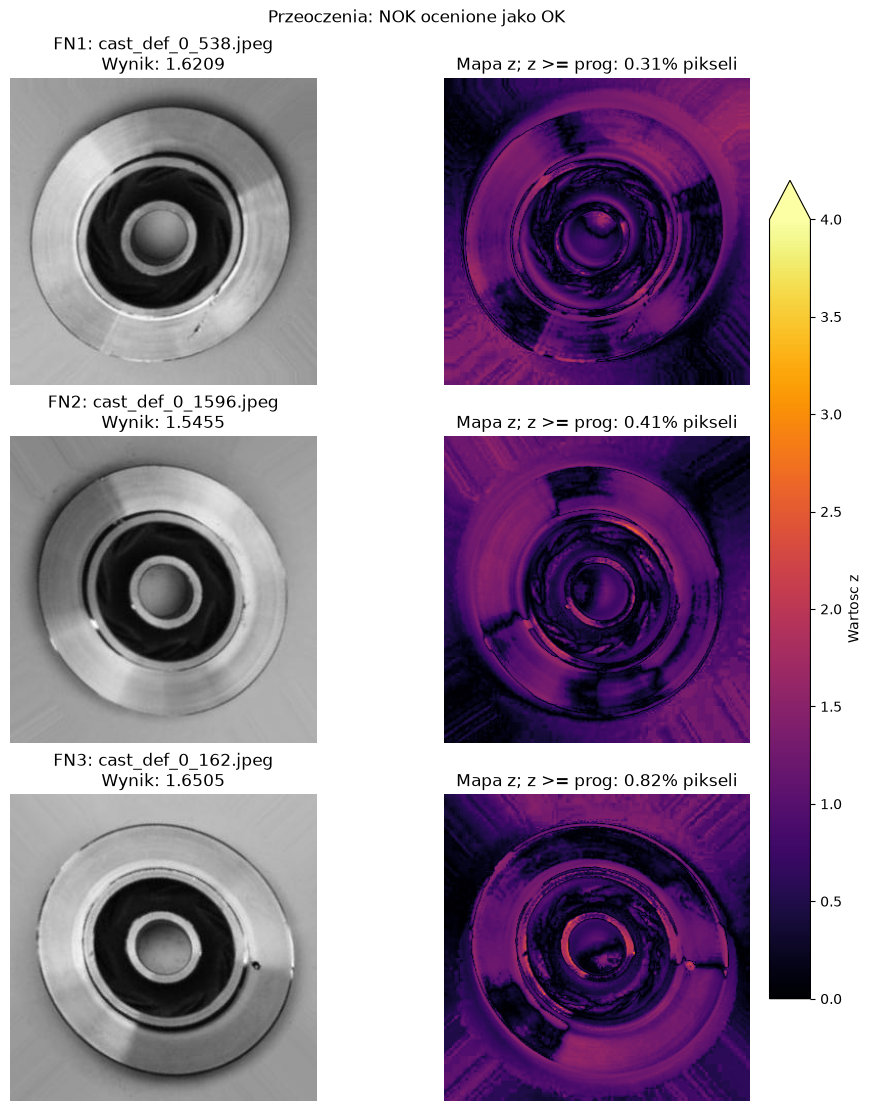

FP1: cast_ok_0_3292.jpeg, wynik=2.9656, z >= prog: 4.74%, max z=12.54
FP2: cast_ok_0_952.jpeg, wynik=2.6219, z >= prog: 2.48%, max z=6.95
FP3: cast_ok_0_31.jpeg, wynik=2.1426, z >= prog: 8.09%, max z=3.53


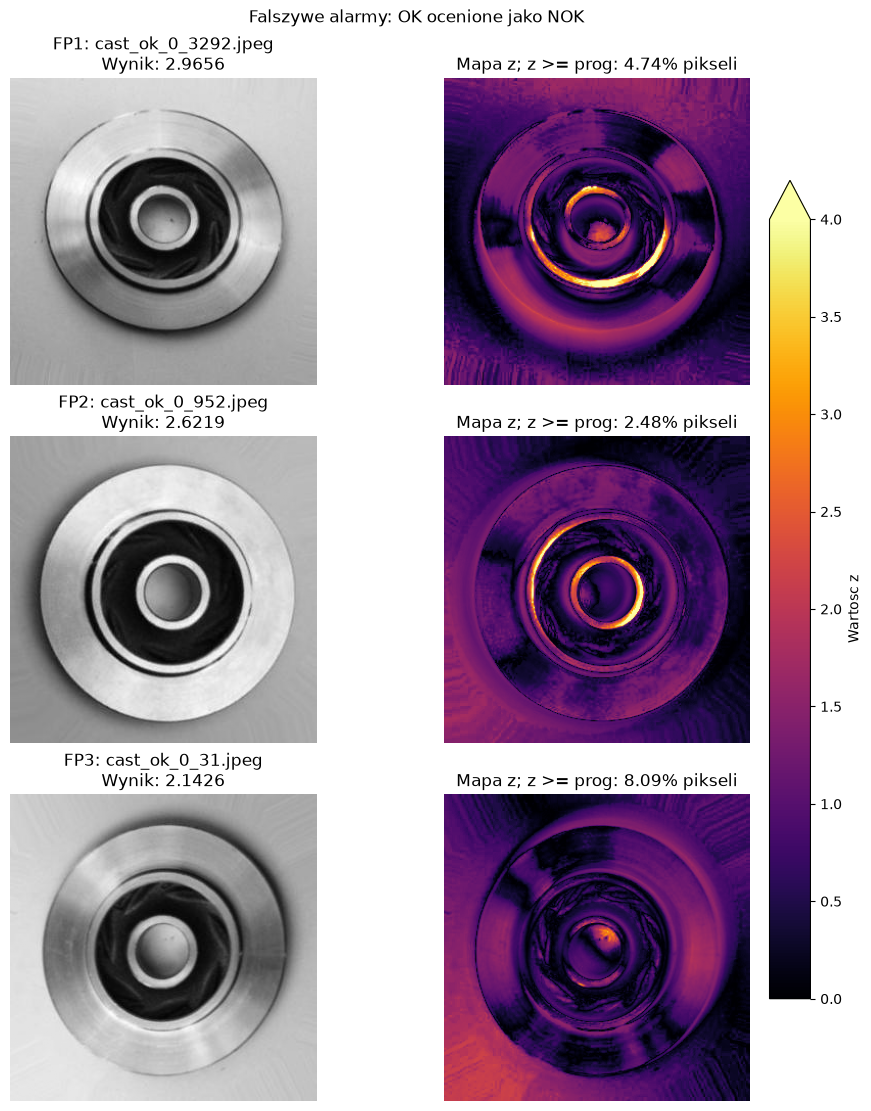

In [36]:
fn_ids = np.flatnonzero(s_nok < t)[:3]
fp_ids = np.flatnonzero(s_ok >= t)[:3]

print("Liczba przeoczen:", np.count_nonzero(s_nok < t))
print("Liczba falszywych alarmow:", np.count_nonzero(s_ok >= t))
print(f"Prog detektora: {t:.4f}")

names = {
    "FN": "Przeoczenia: NOK ocenione jako OK",
    "FP": "Falszywe alarmy: OK ocenione jako NOK"
}

groups = [
    ("FN", fn_ids, test_nok, test_paths_nok, s_nok),
    ("FP", fp_ids, test_ok, test_paths_ok, s_ok)
]

for tag, ids, imgs, paths, scores in groups:
    fig, ax = plt.subplots(
        3, 2, figsize=(9, 11), layout="constrained"
    )
    fig.suptitle(names[tag])

    for row, i in enumerate(ids):
        case = f"{tag}{row + 1}"
        img = imgs[i]

        z = mapa_z(best_fn(img), mean, std)
        pct = 100 * np.mean(z >= t)

        print(
            f"{case}: {paths[i].name}, "
            f"wynik={scores[i]:.4f}, "
            f"z >= prog: {pct:.2f}%, max z={z.max():.2f}"
        )

        ax[row, 0].imshow(
            img, cmap="gray", vmin=0, vmax=255
        )
        ax[row, 0].set_title(
            f"{case}: {paths[i].name}\n"
            f"Wynik: {scores[i]:.4f}"
        )

        im = ax[row, 1].imshow(
            z, cmap="inferno", vmin=0, vmax=4
        )
        ax[row, 1].set_title(
            f"Mapa z; z >= prog: {pct:.2f}% pikseli"
        )

        ax[row, 0].axis("off")
        ax[row, 1].axis("off")

    fig.colorbar(
        im, ax=ax[:, 1], label="Wartosc z",
        extend="max", shrink=0.8
    )
    plt.show()

**Obserwacje i wnioski**

*Czy przeoczenia mają cechę wspólną? Na przykład wadę o małym kontraście albo położoną w obszarze o dużej zmienności? Czy fałszywe alarmy wynikają z wyrobu, czy z warunków rejestracji obrazu? Którą z tych dwóch grup błędów dałoby się usunąć zmianą w torze akwizycji, a nie zmianą algorytmu?*

> 

WNIOSKI:

Przypuszczalne przyczyny pomyłek:

- FN1: drobny ciemny ślad na dolnej części pierścienia ma niewielki wpływ na wynik całego zdjęcia.
- FN2: lokalna nieregularność wewnętrznego pierścienia prawdopodobnie ginie w naturalnej zmienności wzorca.
- FN3: mała ciemna wada po prawej zajmuje zbyt mały obszar, aby podnieść 99. percentyl ponad próg.
- FP1: silna reakcja na obwódki pierścieni sugeruje róznice geometrii lub połozenia oraz wpływ odbić.
- FP2: jasne wewnętrzne krawędzie odstają od wzorca mimo poprawności wyrobu.
- FP3: rozległe odchylenia na tle i pierścieniu sugerują wpływ oświetlenia oraz ułozenia.

W wybranych przeoczeniach mniej niz 1% pikseli mapy przekracza próg. Pokazuje to ograniczenie oceny całego zdjęcia przez 99. percentyl.

Fałszywych alarmów powinno być mniej, jeśli elementy będą ustawiane w tej samej pozycji, przy stałym, równomiernym oświetleniu. Naturalne róznice geometrii oraz małe lokalne wady wymagają równiez poprawy sposobu analizy.

***